# Week 5 — Inventory Analytics

## Objective
Evaluate inventory levels, stock movement, stock health, inventory value, turnover-related indicators, and inventory risk in support of better inventory planning and optimization.

## Goals
- Analyse current inventory value and distribution.
- Evaluate stock movement using the stock ledger.
- Measure product-level inventory demand coverage.
- Develop turnover-related indicators.
- Connect product movement with inventory position.
- Identify high-value and low-movement inventory risk.
- Investigate stock-health indicators carefully.
- Distinguish reliable inventory KPIs from exploratory metrics affected by known data limitations.

In [1]:
import pandas as pd
import numpy as np

inventory_analysis = pd.read_csv(
    "analysis_ready_data/inventory_analysis.csv"
)

product_performance = pd.read_csv(
    "week4_outputs/product_performance.csv"
)

stock_ledger = pd.read_csv(
    "processed_data/stock_ledger_clean.csv"
)

In [2]:
stock_ledger["movement_date"] = pd.to_datetime(
    stock_ledger["movement_date"],
    errors="coerce"
)

In [3]:
print("Inventory rows:", len(inventory_analysis))
print(
    "Unique product-branch combinations:",
    inventory_analysis[
        ["product_id", "branch_id"]
    ].drop_duplicates().shape[0]
)

print("Product performance rows:", len(product_performance))
print("Unique products:", product_performance["product_id"].nunique())

print("Stock ledger rows:", len(stock_ledger))

Inventory rows: 180
Unique product-branch combinations: 180
Product performance rows: 30
Unique products: 30
Stock ledger rows: 237230


In [4]:
product_inventory_value = (
    inventory_analysis
    .groupby(
        [
            "product_id",
            "product_name",
            "category"
        ]
    )
    .agg(
        total_current_stock=("current_stock", "sum"),
        total_inventory_value=("inventory_value", "sum"),
        branch_count=("branch_id", "nunique")
    )
    .reset_index()
)

In [5]:
product_inventory_value["inventory_value_contribution_percent"] = (
    product_inventory_value["total_inventory_value"]
    / product_inventory_value["total_inventory_value"].sum()
    * 100
)

In [6]:
product_inventory_value = product_inventory_value.sort_values(
    "total_inventory_value",
    ascending=False
)

product_inventory_value.head(10)

,product_id,product_name,category,total_current_stock,total_inventory_value,branch_count,inventory_value_contribution_percent
14,P015,Engine Block EB-600,Engine,632583,60411676500,6,21.476448
13,P014,Transmission Assembly TA-800,Transmission,661663,45323915500,6,16.112725
20,P021,Boom Cylinder BC-400,Hydraulic,630617,22449965200,6,7.980999
3,P004,Track Chain TC-45,Undercarriage,638882,20763665000,6,7.381516
18,P019,Swing Motor SWM-350,Hydraulic,622249,19414168800,6,6.901768
9,P010,Turbocharger TB-900,Engine,661248,19110067200,6,6.793660
10,P011,Hydraulic Cylinder HC-200,Hydraulic,650389,13983363500,6,4.971108
0,P001,Hydraulic Pump HP-300,Hydraulic,643984,12203496800,6,4.338363
29,P030,Fuel Pump FP-350,Engine,632290,10369556000,6,3.686394
21,P022,Control Valve CV-75,Hydraulic,647348,8286054400,6,2.945706


In [7]:
branch_inventory_value = (
    inventory_analysis
    .groupby(
        [
            "branch_id",
            "branch_name"
        ]
    )
    .agg(
        total_inventory_value=("inventory_value", "sum"),
        total_current_stock=("current_stock", "sum"),
        product_count=("product_id", "nunique")
    )
    .reset_index()
)

In [8]:
branch_inventory_value["inventory_value_contribution_percent"] = (
    branch_inventory_value["total_inventory_value"]
    / branch_inventory_value["total_inventory_value"].sum()
    * 100
)

In [9]:
branch_inventory_value.sort_values(
    "total_inventory_value",
    ascending=False
)

,branch_id,branch_name,total_inventory_value,total_current_stock,product_count,inventory_value_contribution_percent
1,CHN001,Chennai South Hub,47798163500,3234245,30,16.992324
5,PUN001,Pune Distribution,47728085910,3256263,30,16.967411
2,DEL001,Delhi Central,47709094440,3288670,30,16.960660
3,HYD001,Hyderabad Logistics,47224691630,3245291,30,16.788454
0,AHM001,Ahmedabad West Hub,46129795000,3154992,30,16.399216
4,KOL001,Kolkata East Depot,44702846930,3123805,30,15.891934


In [10]:
category_inventory_value = (
    inventory_analysis
    .groupby("category")
    .agg(
        total_inventory_value=("inventory_value", "sum"),
        total_current_stock=("current_stock", "sum"),
        product_count=("product_id", "nunique")
    )
    .reset_index()
)

In [11]:
category_inventory_value["inventory_value_contribution_percent"] = (
    category_inventory_value["total_inventory_value"]
    / category_inventory_value["total_inventory_value"].sum()
    * 100
)

In [12]:
category_inventory_value.sort_values(
    "total_inventory_value",
    ascending=False
)

,category,total_inventory_value,total_current_stock,product_count,inventory_value_contribution_percent
6,Engine,94074806700,2584941,4,33.443745
8,Hydraulic,76980735240,3851410,6,27.366775
13,Transmission,45323915500,661663,1,16.112725
14,Undercarriage,37039171200,2607045,4,13.167485
5,Electrical,13738763250,1903341,3,4.884152
4,Cooling,4944888000,633960,1,1.757916
3,Cabin,3649973600,651781,1,1.297571
12,Sensors,1746189500,634978,1,0.620773
2,Brakes,1193592600,663107,1,0.424324
7,Filters,827849700,1305127,2,0.294302


In [13]:
inventory_product_strategy = product_inventory_value.merge(
    product_performance[
        [
            "product_id",
            "abc_class",
            "movement_class",
            "profitability_class",
            "demand_stability",
            "priority_group",
            "avg_monthly_units",
            "total_units_sold",
            "total_revenue"
        ]
    ],
    on="product_id",
    how="left",
    validate="one_to_one"
)

In [14]:
print(
    "Missing strategy matches:",
    inventory_product_strategy["abc_class"].isna().sum()
)

print(
    "Rows:",
    len(inventory_product_strategy)
)

Missing strategy matches: 0
Rows: 30


In [15]:
movement_inventory_summary = (
    inventory_product_strategy
    .groupby("movement_class")
    .agg(
        product_count=("product_id", "nunique"),
        total_inventory_value=("total_inventory_value", "sum"),
        total_current_stock=("total_current_stock", "sum")
    )
    .reset_index()
)

movement_inventory_summary[
    "inventory_value_percent"
] = (
    movement_inventory_summary["total_inventory_value"]
    / movement_inventory_summary["total_inventory_value"].sum()
    * 100
)

movement_inventory_summary

,movement_class,product_count,total_inventory_value,total_current_stock,inventory_value_percent
0,Fast Moving,8,47752763740,5197774,16.976184
1,Medium Moving,14,129287077640,8959662,45.961764
2,Slow Moving,8,104252836030,5145830,37.062051


In [16]:
abc_inventory_summary = (
    inventory_product_strategy
    .groupby("abc_class")
    .agg(
        product_count=("product_id", "nunique"),
        total_inventory_value=("total_inventory_value", "sum")
    )
    .reset_index()
)

abc_inventory_summary[
    "inventory_value_percent"
] = (
    abc_inventory_summary["total_inventory_value"]
    / abc_inventory_summary["total_inventory_value"].sum()
    * 100
)

abc_inventory_summary

,abc_class,product_count,total_inventory_value,inventory_value_percent
0,A,9,224029874500,79.642981
1,B,7,42340055150,15.051958
2,C,14,14922747760,5.305061


In [17]:
inventory_product_strategy["inventory_risk_flag"] = np.select(
    [
        (
            inventory_product_strategy["movement_class"] == "Slow Moving"
        )
        & (
            inventory_product_strategy["abc_class"] == "C"
        ),

        (
            inventory_product_strategy["movement_class"] == "Slow Moving"
        ),

        (
            inventory_product_strategy["abc_class"] == "A"
        )
        & (
            inventory_product_strategy["movement_class"] == "Fast Moving"
        )
    ],
    [
        "High Holding Risk",
        "Monitor Slow Movement",
        "Strategic Inventory"
    ],
    default="Normal Review"
)

In [18]:
inventory_product_strategy[
    "inventory_risk_flag"
].value_counts()

inventory_risk_flag
Normal Review            20
Monitor Slow Movement     5
High Holding Risk         3
Strategic Inventory       2
Name: count, dtype: int64

### Inventory Risk Classification

Inventory risk was evaluated by combining Week 4 product importance with product movement.

The exploratory classification identified:

- 2 Strategic Inventory products
- 3 High Holding Risk products
- 5 Monitor Slow Movement products
- 20 Normal Review products

High Holding Risk products are both Class C and Slow Moving, meaning they have relatively low revenue contribution and lower movement.

Strategic Inventory products are both Class A and Fast Moving, making them important candidates for stronger availability monitoring.

This classification is exploratory and does not yet use stock-threshold fields because those fields showed a known scale inconsistency during earlier validation.

In [19]:
inventory_product_strategy["months_of_stock"] = (
    inventory_product_strategy["total_current_stock"]
    / inventory_product_strategy["avg_monthly_units"]
)

In [20]:
inventory_product_strategy[
    [
        "product_id",
        "product_name",
        "total_current_stock",
        "avg_monthly_units",
        "months_of_stock",
        "movement_class",
        "abc_class"
    ]
].sort_values(
    "months_of_stock",
    ascending=False
).head(10)

,product_id,product_name,total_current_stock,avg_monthly_units,months_of_stock,movement_class,abc_class
15,P024,Track Roller TR-60,656188,548.416667,1196.513600,Slow Moving,B
11,P023,Idler Wheel IW-55,661520,559.388889,1182.576224,Slow Moving,B
1,P014,Transmission Assembly TA-800,661663,563.527778,1174.144427,Medium Moving,A
16,P005,Fuel Injector FI-220,658820,562.222222,1171.814229,Slow Moving,C
27,P017,Fan Belt FB-30,659066,568.333333,1159.646921,Medium Moving,C
25,P002,Engine Oil Filter OF-90,655012,568.291667,1152.598284,Medium Moving,C
13,P018,Wheel Rim WR-24,650455,566.000000,1149.213781,Medium Moving,B
19,P012,Brake Pad BP-40,663107,577.069444,1149.093937,Fast Moving,C
22,P013,Seal Kit SK-15,634580,554.541667,1144.332407,Slow Moving,C
17,P025,Cabin Glass CG-20,651781,570.708333,1142.056217,Medium Moving,C


In [21]:
inventory_product_strategy["months_of_stock"].describe()

count      30.000000
mean     1125.788612
std        31.595092
min      1070.638752
25%      1103.133510
50%      1122.376519
75%      1147.903555
max      1196.513600
Name: months_of_stock, dtype: float64

### Inventory Coverage Limitation

An exploratory months-of-stock metric was calculated using current stock divided by average monthly units sold.

The resulting values ranged from approximately 1,071 to 1,197 months of stock coverage.

These values are operationally unrealistic and are consistent with the inventory-scale anomaly identified during earlier data validation.

Therefore, the calculated months-of-stock metric will not be used as a final inventory KPI or as the basis for inventory optimization recommendations.

Instead, inventory turnover and movement will be evaluated using historical stock-ledger transactions and relative product movement indicators.

In [22]:
product_stock_movement = (
    stock_ledger
    .groupby(["product_id", "movement_type"])
    .agg(
        total_quantity=("quantity", "sum"),
        movement_count=("movement_id", "count")
    )
    .reset_index()
)

In [23]:
quantity_pivot = (
    product_stock_movement
    .pivot(
        index="product_id",
        columns="movement_type",
        values="total_quantity"
    )
    .fillna(0)
    .reset_index()
)

quantity_pivot.columns.name = None

quantity_pivot = quantity_pivot.rename(
    columns={
        "IN": "total_stock_in",
        "OUT": "total_stock_out",
        "ADJUSTMENT": "total_adjustment"
    }
)

In [24]:
frequency_pivot = (
    product_stock_movement
    .pivot(
        index="product_id",
        columns="movement_type",
        values="movement_count"
    )
    .fillna(0)
    .reset_index()
)

frequency_pivot.columns.name = None

frequency_pivot = frequency_pivot.rename(
    columns={
        "IN": "stock_in_events",
        "OUT": "stock_out_events",
        "ADJUSTMENT": "adjustment_events"
    }
)

In [25]:
stock_movement_summary = quantity_pivot.merge(
    frequency_pivot,
    on="product_id",
    how="left",
    validate="one_to_one"
)

In [26]:
stock_movement_summary["out_to_in_ratio"] = (
    stock_movement_summary["total_stock_out"]
    / stock_movement_summary["total_stock_in"]
)

stock_movement_summary["net_stock_flow"] = (
    stock_movement_summary["total_stock_in"]
    - stock_movement_summary["total_stock_out"]
)

In [27]:
stock_movement_summary[
    [
        "product_id",
        "total_stock_in",
        "total_stock_out",
        "total_adjustment",
        "stock_in_events",
        "stock_out_events",
        "out_to_in_ratio",
        "net_stock_flow"
    ]
].head(10)

,product_id,total_stock_in,total_stock_out,total_adjustment,stock_in_events,stock_out_events,out_to_in_ratio,net_stock_flow
0,P001,680366,37672,2000,4200,3614,0.055370,642694
1,P002,691550,37180,1996,4312,3541,0.053763,654370
2,P003,686563,37920,1904,4310,3608,0.055232,648643
3,P004,675295,37255,2102,4209,3509,0.055168,638040
4,P005,694855,36870,2552,4356,3545,0.053061,657985
5,P006,683590,37914,2416,4277,3622,0.055463,645676
6,P007,693266,38098,2366,4322,3602,0.054954,655168
7,P008,660785,37312,1956,4197,3554,0.056466,623473
8,P009,667762,37191,2270,4181,3513,0.055695,630571
9,P010,699397,38616,2049,4349,3651,0.055213,660781


In [28]:
stock_movement_summary["out_to_in_ratio"].describe()

count    30.000000
mean      0.055166
std       0.001483
min       0.052021
25%       0.054050
50%       0.055244
75%       0.056403
max       0.057416
Name: out_to_in_ratio, dtype: float64

In [29]:
movement_turnover = stock_movement_summary.merge(
    product_performance[
        [
            "product_id",
            "movement_score",
            "movement_class",
            "total_units_sold"
        ]
    ],
    on="product_id",
    how="left",
    validate="one_to_one"
)

In [30]:
movement_turnover["stock_out_quantity_percentile"] = (
    movement_turnover["total_stock_out"]
    .rank(pct=True)
)

movement_turnover["stock_out_frequency_percentile"] = (
    movement_turnover["stock_out_events"]
    .rank(pct=True)
)

In [31]:
movement_turnover["turnover_score"] = (
    movement_turnover["stock_out_quantity_percentile"]
    + movement_turnover["stock_out_frequency_percentile"]
    + movement_turnover["movement_score"]
) / 3

In [32]:
turnover_q25 = movement_turnover["turnover_score"].quantile(0.25)
turnover_q75 = movement_turnover["turnover_score"].quantile(0.75)

movement_turnover["turnover_class"] = np.select(
    [
        movement_turnover["turnover_score"] >= turnover_q75,
        movement_turnover["turnover_score"] <= turnover_q25
    ],
    [
        "High Turnover",
        "Low Turnover"
    ],
    default="Medium Turnover"
)

In [33]:
movement_turnover["turnover_class"].value_counts()

turnover_class
Medium Turnover    14
High Turnover       8
Low Turnover        8
Name: count, dtype: int64

### Relative Inventory Turnover Indicator

A standard accounting inventory turnover ratio could not be calculated reliably because the current inventory snapshot shows a known scale inconsistency.

Instead, a relative turnover indicator was created using:

- Historical stock-out quantity
- Stock-out event frequency
- Product sales movement score

Products were then classified relative to the observed distribution into High, Medium, and Low Turnover groups.

This indicator reflects relative inventory movement within the dataset and should not be interpreted as a standard accounting turnover ratio.

In [34]:
inventory_turnover_strategy = inventory_product_strategy.merge(
    movement_turnover[
        [
            "product_id",
            "turnover_score",
            "turnover_class",
            "out_to_in_ratio",
            "net_stock_flow"
        ]
    ],
    on="product_id",
    how="left",
    validate="one_to_one"
)

In [35]:
inventory_turnover_strategy["inventory_action_group"] = np.select(
    [
        (
            inventory_turnover_strategy["abc_class"] == "A"
        )
        & (
            inventory_turnover_strategy["turnover_class"] == "High Turnover"
        ),

        (
            inventory_turnover_strategy["abc_class"] == "C"
        )
        & (
            inventory_turnover_strategy["turnover_class"] == "Low Turnover"
        ),

        (
            inventory_turnover_strategy["turnover_class"] == "Low Turnover"
        ),

        (
            inventory_turnover_strategy["turnover_class"] == "High Turnover"
        )
    ],
    [
        "Protect Availability",
        "Reduce / Review Holding",
        "Monitor Inventory",
        "Maintain Supply"
    ],
    default="Standard Control"
)

In [36]:
inventory_turnover_strategy[
    "inventory_action_group"
].value_counts()

inventory_action_group
Standard Control           14
Monitor Inventory           6
Maintain Supply             6
Protect Availability        2
Reduce / Review Holding     2
Name: count, dtype: int64

### Inventory Action Framework

A relative inventory action framework was created by combining product revenue importance with the inventory turnover classification.

The resulting groups are:

- Protect Availability: 2 products
- Maintain Supply: 6 products
- Standard Control: 14 products
- Monitor Inventory: 6 products
- Reduce / Review Holding: 2 products

Products classified as Protect Availability are both Class A and High Turnover, making them important candidates for stronger stock availability monitoring.

Products classified as Reduce / Review Holding are both Class C and Low Turnover, making them potential candidates for reducing or reviewing inventory holding.

Because the current inventory snapshot contains a known scale inconsistency, these groups are strategic relative indicators rather than final reorder or stock-level recommendations.

In [37]:
analysis_date = stock_ledger["movement_date"].max()

print("Latest stock movement date:", analysis_date)

Latest stock movement date: 2025-01-28 00:00:00


In [38]:
product_activity = (
    stock_ledger
    .groupby("product_id")
    .agg(
        last_movement_date=("movement_date", "max"),
        first_movement_date=("movement_date", "min"),
        total_movement_events=("movement_id", "count")
    )
    .reset_index()
)

In [39]:
product_activity["days_since_last_movement"] = (
    analysis_date
    - product_activity["last_movement_date"]
).dt.days

In [40]:
product_activity["days_since_last_movement"].describe()

count    30.000000
mean      3.333333
std       3.165910
min       0.000000
25%       0.250000
50%       2.500000
75%       6.000000
max       9.000000
Name: days_since_last_movement, dtype: float64

In [41]:
activity_q25 = product_activity["days_since_last_movement"].quantile(0.25)
activity_q75 = product_activity["days_since_last_movement"].quantile(0.75)

product_activity["activity_status"] = np.select(
    [
        product_activity["days_since_last_movement"] <= activity_q25,
        product_activity["days_since_last_movement"] >= activity_q75
    ],
    [
        "Recently Active",
        "Less Active"
    ],
    default="Moderately Active"
)

In [42]:
product_activity["activity_status"].value_counts()

activity_status
Moderately Active    13
Less Active           9
Recently Active       8
Name: count, dtype: int64

In [43]:
inventory_turnover_strategy = inventory_turnover_strategy.merge(
    product_activity[
        [
            "product_id",
            "last_movement_date",
            "days_since_last_movement",
            "total_movement_events",
            "activity_status"
        ]
    ],
    on="product_id",
    how="left",
    validate="one_to_one"
)

### Stock Activity and Aging

Historical stock-ledger activity shows that all products have recent inventory movements.

Days since the most recent movement ranged from 0 to 9 days, with a median of approximately 2.5 days.

Therefore, there is no strong evidence of dead or inactive products at the overall product level based on stock-movement recency.

The activity categories used in this analysis represent relative differences within the dataset and should not be interpreted as traditional inventory-aging categories.

In [44]:
product_branch_movement = (
    stock_ledger
    .groupby(
        ["product_id", "branch_id", "movement_type"]
    )
    .agg(
        total_quantity=("quantity", "sum"),
        movement_events=("movement_id", "count"),
        last_movement_date=("movement_date", "max")
    )
    .reset_index()
)

In [45]:
product_branch_quantity = (
    product_branch_movement
    .pivot_table(
        index=["product_id", "branch_id"],
        columns="movement_type",
        values="total_quantity",
        fill_value=0
    )
    .reset_index()
)

product_branch_quantity.columns.name = None

product_branch_quantity = product_branch_quantity.rename(
    columns={
        "IN": "stock_in_units",
        "OUT": "stock_out_units",
        "ADJUSTMENT": "adjustment_units"
    }
)

In [46]:
product_branch_events = (
    product_branch_movement
    .pivot_table(
        index=["product_id", "branch_id"],
        columns="movement_type",
        values="movement_events",
        fill_value=0
    )
    .reset_index()
)

product_branch_events.columns.name = None

product_branch_events = product_branch_events.rename(
    columns={
        "IN": "stock_in_events",
        "OUT": "stock_out_events",
        "ADJUSTMENT": "adjustment_events"
    }
)

In [47]:
product_branch_activity = (
    stock_ledger
    .groupby(["product_id", "branch_id"])
    .agg(
        last_movement_date=("movement_date", "max")
    )
    .reset_index()
)

product_branch_activity["days_since_last_movement"] = (
    analysis_date
    - product_branch_activity["last_movement_date"]
).dt.days

In [48]:
product_branch_stock_health = (
    inventory_analysis
    .merge(
        product_branch_quantity,
        on=["product_id", "branch_id"],
        how="left",
        validate="one_to_one"
    )
    .merge(
        product_branch_events,
        on=["product_id", "branch_id"],
        how="left",
        validate="one_to_one"
    )
    .merge(
        product_branch_activity,
        on=["product_id", "branch_id"],
        how="left",
        validate="one_to_one"
    )
)

In [49]:
print("Inventory rows:", len(inventory_analysis))
print(
    "Product-branch stock health rows:",
    len(product_branch_stock_health)
)

print(
    "Difference:",
    len(product_branch_stock_health)
    - len(inventory_analysis)
)

Inventory rows: 180
Product-branch stock health rows: 180
Difference: 0


In [50]:
product_branch_stock_health[
    "days_since_last_movement"
].describe()

count    180.000000
mean       9.733333
std        5.016843
min        0.000000
25%        7.000000
50%       10.000000
75%       13.000000
max       28.000000
Name: days_since_last_movement, dtype: float64

### Product-Branch Stock Activity

Stock activity was also evaluated at the product-branch level to identify warehouse-specific inactivity that may be hidden by product-level aggregation.

Across the 180 product-branch combinations:

- Minimum days since last movement: 0
- Median: approximately 10 days
- Mean: approximately 9.7 days
- Maximum: 28 days

This shows that while all products are active overall, some product-branch combinations experience noticeably less frequent stock movement.

Therefore, warehouse-level inventory monitoring should consider product-branch activity rather than relying only on product-level activity.

In [51]:
pb_q25 = product_branch_stock_health[
    "days_since_last_movement"
].quantile(0.25)

pb_q75 = product_branch_stock_health[
    "days_since_last_movement"
].quantile(0.75)

product_branch_stock_health["branch_activity_status"] = np.select(
    [
        product_branch_stock_health["days_since_last_movement"] <= pb_q25,
        product_branch_stock_health["days_since_last_movement"] >= pb_q75
    ],
    [
        "Recently Active",
        "Lower Activity"
    ],
    default="Moderately Active"
)

In [52]:
product_branch_stock_health[
    "branch_activity_status"
].value_counts()

branch_activity_status
Moderately Active    83
Lower Activity       50
Recently Active      47
Name: count, dtype: int64

In [53]:
product_branch_stock_health = product_branch_stock_health.merge(
    movement_turnover[
        [
            "product_id",
            "turnover_class"
        ]
    ],
    on="product_id",
    how="left",
    validate="many_to_one"
)

In [54]:
product_branch_stock_health["stock_health_flag"] = np.select(
    [
        (
            product_branch_stock_health["branch_activity_status"]
            == "Lower Activity"
        )
        & (
            product_branch_stock_health["turnover_class"]
            == "Low Turnover"
        ),

        (
            product_branch_stock_health["branch_activity_status"]
            == "Lower Activity"
        ),

        (
            product_branch_stock_health["turnover_class"]
            == "High Turnover"
        )
    ],
    [
        "Potential Stagnation",
        "Monitor Activity",
        "Healthy Movement"
    ],
    default="Normal"
)

In [55]:
product_branch_stock_health[
    "stock_health_flag"
].value_counts()

stock_health_flag
Normal                  97
Monitor Activity        35
Healthy Movement        33
Potential Stagnation    15
Name: count, dtype: int64

### Product-Branch Stock Health

A stock-health indicator was created using historical movement activity and relative product turnover rather than the unreliable current-stock threshold fields.

Across the 180 product-branch combinations:

- 97 were classified as Normal.
- 35 require Activity Monitoring.
- 33 showed Healthy Movement.
- 15 were classified as Potential Stagnation.

Potential Stagnation identifies product-branch combinations that show both relatively lower recent movement and low overall product turnover.

These records should be reviewed more closely because they may represent inventory locations where stock is moving less efficiently.

In [56]:
stagnation_by_branch = (
    product_branch_stock_health[
        product_branch_stock_health["stock_health_flag"]
        == "Potential Stagnation"
    ]
    .groupby(["branch_id", "branch_name"])
    .agg(
        stagnation_cases=("product_id", "count"),
        affected_products=("product_id", "nunique"),
        inventory_value_at_risk=("inventory_value", "sum")
    )
    .reset_index()
    .sort_values(
        "stagnation_cases",
        ascending=False
    )
)

stagnation_by_branch

,branch_id,branch_name,stagnation_cases,affected_products,inventory_value_at_risk
4,KOL001,Kolkata East Depot,4,4,11729243350
2,DEL001,Delhi Central,3,3,7747244540
3,HYD001,Hyderabad Logistics,3,3,9353204300
5,PUN001,Pune Distribution,3,3,8603982200
1,CHN001,Chennai South Hub,1,1,929207600
0,AHM001,Ahmedabad West Hub,1,1,3247042500


In [57]:
stagnation_by_product = (
    product_branch_stock_health[
        product_branch_stock_health["stock_health_flag"]
        == "Potential Stagnation"
    ]
    .groupby(["product_id", "product_name"])
    .agg(
        affected_branches=("branch_id", "nunique"),
        stagnation_cases=("branch_id", "count"),
        inventory_value_at_risk=("inventory_value", "sum")
    )
    .reset_index()
    .sort_values(
        ["affected_branches", "inventory_value_at_risk"],
        ascending=[False, False]
    )
)

stagnation_by_product

,product_id,product_name,affected_branches,stagnation_cases,inventory_value_at_risk
2,P014,Transmission Assembly TA-800,4,4,30278096000
0,P004,Track Chain TC-45,2,2,6823407500
3,P018,Wheel Rim WR-24,2,2,1721385000
5,P024,Track Roller TR-60,2,2,1572892200
1,P013,Seal Kit SK-15,2,2,203205950
6,P026,Grease Cartridge GC-5,2,2,37596240
4,P023,Idler Wheel IW-55,1,1,973341600


### Branch-Level Potential Stagnation

Potential stagnation was evaluated across product-branch combinations using lower recent activity combined with low product turnover.

Kolkata East Depot showed the highest number of potential stagnation cases, with four affected products.

Hyderabad Logistics, Pune Distribution, and Delhi Central each showed three affected products, while Chennai South Hub and Ahmedabad West Hub showed one case each.

Kolkata East Depot also had the highest inventory value associated with flagged product-branch combinations.

Because the current inventory-value scale contains a known data limitation, these inventory values are used primarily for relative comparison rather than as exact optimization amounts.

The branch-level pattern provides an important link between inventory health and warehouse performance and will be investigated further during Week 6 Warehouse Analytics.

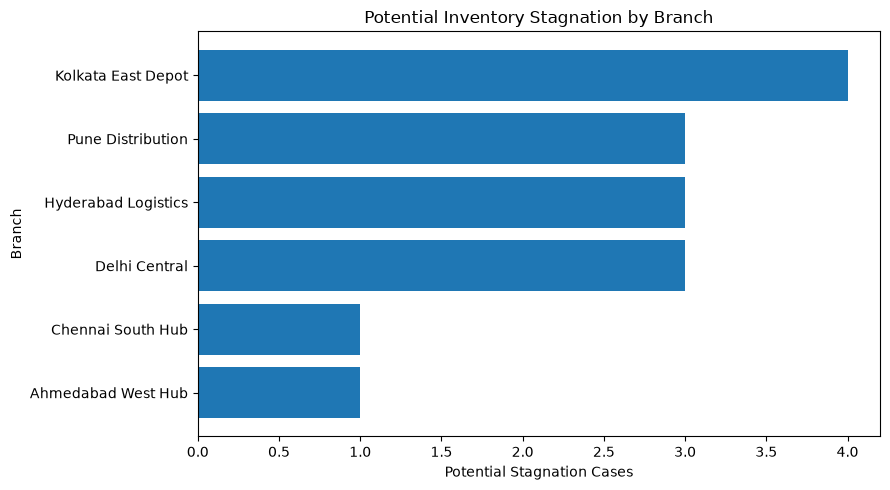

In [58]:
import matplotlib.pyplot as plt

branch_plot = stagnation_by_branch.sort_values(
    "stagnation_cases",
    ascending=True
)

plt.figure(figsize=(9, 5))

plt.barh(
    branch_plot["branch_name"],
    branch_plot["stagnation_cases"]
)

plt.xlabel("Potential Stagnation Cases")
plt.ylabel("Branch")
plt.title("Potential Inventory Stagnation by Branch")

plt.tight_layout()
plt.show()

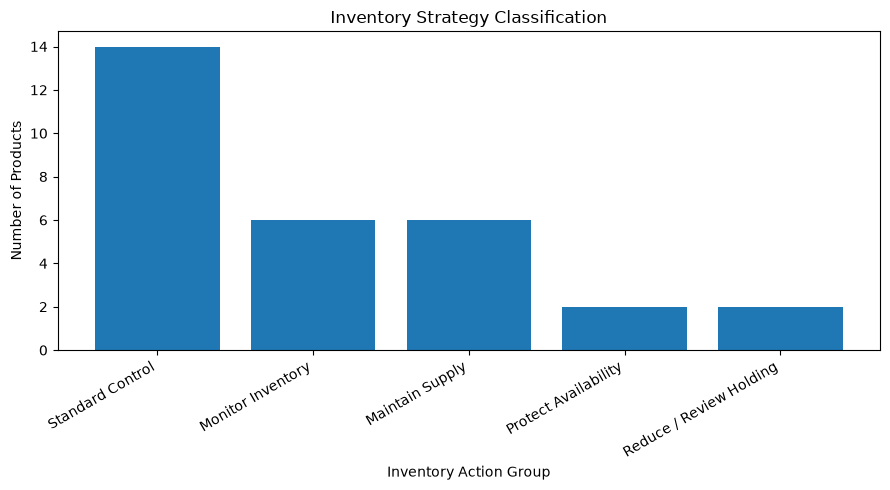

In [59]:
action_counts = (
    inventory_turnover_strategy["inventory_action_group"]
    .value_counts()
)

plt.figure(figsize=(9, 5))

plt.bar(
    action_counts.index,
    action_counts.values
)

plt.xlabel("Inventory Action Group")
plt.ylabel("Number of Products")
plt.title("Inventory Strategy Classification")

plt.xticks(rotation=30, ha="right")

plt.tight_layout()
plt.show()

In [60]:
print("Product-level inventory rows:", len(inventory_turnover_strategy))
print(
    "Unique products:",
    inventory_turnover_strategy["product_id"].nunique()
)

print(
    "Product-branch stock health rows:",
    len(product_branch_stock_health)
)

print(
    "Unique product-branch combinations:",
    product_branch_stock_health[
        ["product_id", "branch_id"]
    ].drop_duplicates().shape[0]
)

print(
    "Missing turnover classes:",
    inventory_turnover_strategy["turnover_class"].isna().sum()
)

print(
    "Missing stock health flags:",
    product_branch_stock_health["stock_health_flag"].isna().sum()
)

Product-level inventory rows: 30
Unique products: 30
Product-branch stock health rows: 180
Unique product-branch combinations: 180
Missing turnover classes: 0
Missing stock health flags: 0


In [61]:
import os

os.makedirs("week5_outputs", exist_ok=True)

product_inventory_value.to_csv(
    "week5_outputs/product_inventory_value.csv",
    index=False
)

inventory_turnover_strategy.to_csv(
    "week5_outputs/inventory_turnover_strategy.csv",
    index=False
)

product_branch_stock_health.to_csv(
    "week5_outputs/product_branch_stock_health.csv",
    index=False
)

stagnation_by_branch.to_csv(
    "week5_outputs/stagnation_by_branch.csv",
    index=False
)

stagnation_by_product.to_csv(
    "week5_outputs/stagnation_by_product.csv",
    index=False
)

print("Week 5 outputs exported successfully.")

Week 5 outputs exported successfully.


In [62]:
for file in os.listdir("week5_outputs"):
    print(file)

inventory_turnover_strategy.csv
product_branch_stock_health.csv
product_inventory_value.csv
stagnation_by_branch.csv
stagnation_by_product.csv
